# Markov Chains and Tumor Heterogeneity


## Background

Why are tumors so hard to treat? Why have we been fighting the "War on Cancer" for over 50 years? 

One key reason is that a tumor isn't made up of a single kind of cell. If it was, we could find a single drug that would target said cell, and kill all of them, without them coming back. However, most tumors are mixes of different types of cancer cells. A breast cancer tumor will only contain breast tumor cells, but those breast tumor cells may be clustered in different states-- some of which are sensitive to drugs, some of which are naturally resistant, and some of which can transition from one state to another. In fact, drug treatment is often the *force* that helps tumor cells transition from sensitive to resistant, meaning the treatment itself is worsening the disease it is trying to treat.

## The lab goal: 
>**Simulate a patient's tumor and figure out what combination of drugs is likely to be effective at killing the tumor.**

If we can track how cells change state *within a single tumor* under drugs, then we can predict what might happen to a patient treated with said drug. To answer that we need to know **how often a cell in each state moves to each other state during one treatment cycle**. That is a transition matrix, and a transition matrix lets us forecast what any tumor looks like after many cycles.

In this lab you will:
   
1. **Build a transition matrix.** Use lineage tags to match each cell at time point A to its descendant at time point B, then count and normalize.
2. **Evolve a distribution.** Start from each single state, and from a mixed tumor, and see where each one ends up.
3. **Simulate random walks and whole tumors.** Follow individual cells by drawing random numbers, then simulate many tumors to estimate how likely each one is to be cured or to relapse.
4. **Find which tumors each drug can cure**, and see why a mixed tumor can't be cured by either drug alone.


Note: **The data is simulated.** The states and their marker genes are modelled on PC9 cells (Oren et al. 2021, *Nature* 596:576), but every count was generated by a script, and how each state responds to each drug is vastly simplified.

## The data

**A little background:**

Lung cancer cells carry a mutant EGFR gene and depend on it to grow. We compare two
drugs:

- **osimertinib**, which blocks EGFR, and
- **docetaxel**, a chemotherapy that kills cells while they divide.
- We will also look at how the cells evolve under no treatment ("drug holiday")

You do not need to understand biology or cancer to complete this lab; the key thing is you have drugs with different effects on cells within a single tumor.

**The dataset:**

Every cell carries something called a  **lineage tag**: a short DNA barcode inserted into its genome, inherited by its descendants. For each drug, one sample is:

1. sequenced at **time point A**, before treatment;
2. treated for **one cycle**;
3. sequenced again at **time point B**.

A tag that appears at both time points links a cell at A to its descendant at B. **A tag seen at A but missing at B means that cell died.** We make one big simplifying assumption: each tag maps one cell at A to *at most one* cell at B.


In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

rng = np.random.default_rng(5030)
plt.rcParams["figure.dpi"] = 110

In [2]:
STATE_ORDER = ["S-G1", "S-syn", "S-G2M", "P",
           "NCP", "CP", "MDR"] 
STATE_COLORS = dict(zip(STATE_ORDER, sns.color_palette("Set2", len(STATE_ORDER))))
STATE_COLORS["cleared"] = "#8a8984"  

In [3]:
cells = pd.read_csv("cell_data.csv")
cells.head()

,Unnamed: 0,experiment,timepoint,lineage_tag,umap_x,umap_y,state
0,0,osimertinib,A,tago-02305,14.189159,7.205170,S-G1
1,1,osimertinib,B,tago-01560,1.031097,13.491245,P
2,2,osimertinib,A,tago-02253,14.651874,7.435656,S-G1
3,3,osimertinib,A,tago-01478,13.919818,-3.705924,S-syn
4,4,osimertinib,A,tago-02626,14.527276,6.953301,S-G1


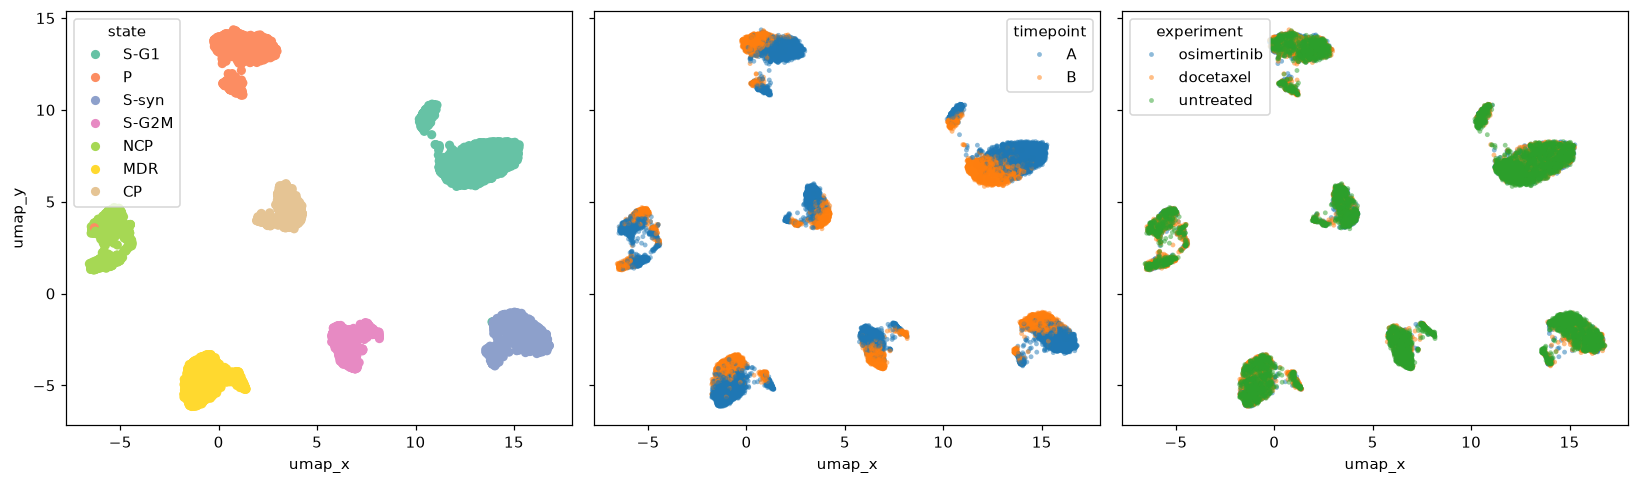

In [4]:
import seaborn as sns
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True, sharey=True)
sns.scatterplot(cells, x = "umap_x", y ="umap_y", hue = "state", ax = axes[0], palette = "Set2", linewidth=0)
sns.scatterplot(cells, x = "umap_x", y ="umap_y", hue = "timepoint", ax = axes[1],s=10, alpha=0.5, linewidth=0)
sns.scatterplot(cells, x = "umap_x", y ="umap_y", hue = "experiment", ax = axes[2],s=10, alpha=0.5, linewidth=0)
plt.tight_layout()
plt.show()

<img src="state_diagram_v2.png">

## 2. Build the transition matrix for the Osimertinib experiment

Start with the osimertinib experiment.

A transition matrix $P$ has one row per state at time point A and one column
per state at time point B:

$$
P_{ij} \;=\; \Pr[\,X_{t+1} = j \mid X_t = i\,]
\;\approx\; \frac{\#\{\text{cells in state } i \text{ at A whose tag is in state } j \text{ at B}\}}
                 {\#\{\text{cells in state } i \text{ at A}\}}.
$$

In the code below, we will start with just the osimertinib experiment (timepoints A and B), and look at where each tag was in A and where it moved to in B. 

**Where does a cell that died end up?** We add an eighth outcome, `"cleared"`, for tags present at A and missing at B.

In [5]:
osi = cells[cells["experiment"] == "osimertinib"]
at_A = osi[osi.timepoint == "A"][["lineage_tag", "state"]]
at_B = osi[osi.timepoint == "B"][["lineage_tag", "state"]]

pairs = pd.merge(at_A, at_B, on="lineage_tag", how="left", suffixes=("_A", "_B"))
pairs["state_B"] = pairs["state_B"].fillna("cleared")

pairs.head()

,lineage_tag,state_A,state_B
0,tago-02305,S-G1,cleared
1,tago-02253,S-G1,cleared
2,tago-01478,S-syn,NCP
3,tago-02626,S-G1,P
4,tago-01487,P,P


In [6]:
STATES = [s for s in STATE_ORDER if s in set(cells["state"])]   # states in a fixed order
OUTCOMES = STATES + ["cleared"]
counts = (pd.crosstab(pairs.state_A, pairs.state_B)
            .reindex(index=STATES, columns=OUTCOMES, fill_value=0))
P_hat = counts.div(counts.sum(axis=1), axis=0)

In [47]:
counts

state_B,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
state_A,,,,,,,,
S-G1,91,17,11,154,41,0,0,437
S-syn,27,23,17,38,16,0,0,333
S-G2M,8,13,20,20,0,0,0,219
P,47,11,8,160,75,0,0,154
NCP,19,0,0,31,153,0,0,109
CP,0,0,0,0,0,279,0,0
MDR,20,14,10,14,0,0,82,329


In [7]:
assert np.allclose(P_hat.sum(axis=1), 1), "Every row should sum to 1."


In [8]:
print("transition counts:")
display(counts)
print("estimated transition matrix (osimertinib, one cycle):")
P_hat.round(3)

transition counts:


state_B,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
state_A,,,,,,,,
S-G1,91,17,11,154,41,0,0,437
S-syn,27,23,17,38,16,0,0,333
S-G2M,8,13,20,20,0,0,0,219
P,47,11,8,160,75,0,0,154
NCP,19,0,0,31,153,0,0,109
CP,0,0,0,0,0,279,0,0
MDR,20,14,10,14,0,0,82,329


estimated transition matrix (osimertinib, one cycle):


state_B,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
state_A,,,,,,,,
S-G1,0.121,0.023,0.015,0.205,0.055,0.0,0.000,0.582
S-syn,0.059,0.051,0.037,0.084,0.035,0.0,0.000,0.733
S-G2M,0.029,0.046,0.071,0.071,0.000,0.0,0.000,0.782
P,0.103,0.024,0.018,0.352,0.165,0.0,0.000,0.338
NCP,0.061,0.000,0.000,0.099,0.490,0.0,0.000,0.349
CP,0.000,0.000,0.000,0.000,0.000,1.0,0.000,0.000
MDR,0.043,0.030,0.021,0.030,0.000,0.0,0.175,0.701


Because some of the cells die and get cleared, we added an extra state they could move to. To use this transition matrix over and over again (for example, if a patient got two rounds of osimertinib), we need it to have the *same* rows and columns-- **the transition matrix should be able to tell us where a cell moves to for *any state at all, including "cleared."*** So we will **add another row to the transition matrix:** if a cell starts in "cleared" it stays cleared with probability = 1.

### Make it square

We add that row by **assumption**: a cleared cell stays cleared with probability 1. A state you can never leave is called an **absorbing state**.

In [24]:
#add a cleared row that stays cleared with p = 1
P_hat.loc["cleared"] = pd.Series({rowname: (1 if rowname == "cleared" else 0) for rowname in P_hat.columns})
P_hat

state_B,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
state_A,,,,,,,,
S-G1,0.121172,0.022636,0.014647,0.205060,0.054594,0.0,0.00000,0.581891
S-syn,0.059471,0.050661,0.037445,0.083700,0.035242,0.0,0.00000,0.733480
S-G2M,0.028571,0.046429,0.071429,0.071429,0.000000,0.0,0.00000,0.782143
P,0.103297,0.024176,0.017582,0.351648,0.164835,0.0,0.00000,0.338462
NCP,0.060897,0.000000,0.000000,0.099359,0.490385,0.0,0.00000,0.349359
CP,0.000000,0.000000,0.000000,0.000000,0.000000,1.0,0.00000,0.000000
MDR,0.042644,0.029851,0.021322,0.029851,0.000000,0.0,0.17484,0.701493
cleared,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.00000,1.000000


In [10]:
STATES = [s for s in STATE_ORDER if s in set(cells["state"])]
OUTCOMES = STATES + ["cleared"]

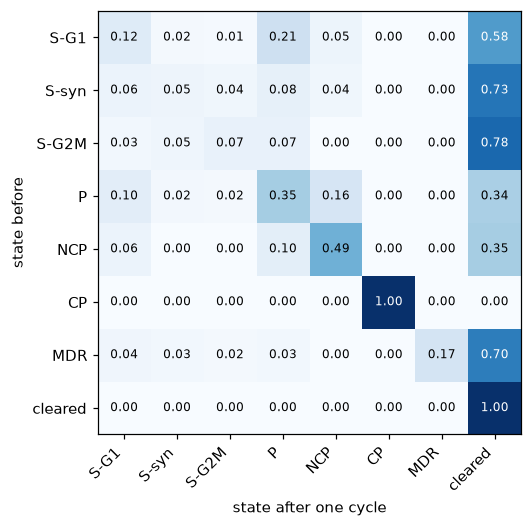

In [11]:
def show_matrix(P, title=None, ax=None):
    ax = ax or plt.subplots(figsize=(6.5, 5))[1]
    values = P.to_numpy()                      # numbers for imshow and P[i, j]
    ax.imshow(values, cmap="Blues", vmin=0, vmax=1)
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            ax.text(j, i, f"{values[i, j]:.2f}", ha="center", va="center",
                    color="white" if values[i, j] > 0.5 else "black", fontsize=8)
    ax.set_xticks(range(values.shape[1]), P.columns, rotation=45, ha="right")
    ax.set_yticks(range(values.shape[0]), P.index)
    ax.set_xlabel("state after one cycle"); ax.set_ylabel("state before")
    ax.set_title(title)

show_matrix(P_hat)

<div class='alert alert-info'>
<b>Question:</b> reading P_hat and looking at the matrix, are any of the measured states other than "cleared" also (approximately) absorbing under osimertinib? If so, what does this mean in terms of the response to drug treatment? If not, what does it mean?
</div>

Based on P_hat and the matrix, it looks like CP is an absorbing state. Based on this data, there is a 100% proabbility that the state will remain CP if it began in CP after one cycle. In terms of the response to drug treatment, this means that the drug will have no effect on this state, and it has thus become resistant

## 3. Simulate a tumor comprising 1 cell type: Evolve a distribution

Write the state of the whole tumor as a **row vector** $\pi_t$: entry $j$ is the
probability that a randomly chosen original cell is in state $j$ after $t$
cycles. One cycle multiplies by $P$:

$$
\pi_{t+1} = \pi_t P
\qquad\Longrightarrow\qquad
\pi_t = \pi_0 P^t .
$$

Start with the simplest $\pi_0$: a **basis vector**, all probability on one
state. $e = (1, 0, 0, 0, 0, 0, 0, 0)$ asks "what happens to a
cell that starts in state S-G1?" Equivalently, "what happens to a tumor made entirely of S-G1 cells?"

**Predict first.** Before running the code: look at the transition matrix: which starting states can osimertinib eliminate completely? Which can't it? 

In [12]:
def evolve(pi0, P, n_cycles):
    '''Return an array of shape (n_cycles + 1, n_states) whose row t is pi0 @ P^t.'''
    traj = [np.asarray(pi0, dtype=float)]
    for _ in range(n_cycles):
        traj.append(traj[-1] @ P)
    return np.array(traj)

In [13]:
def basis(starting_state, P):
    '''All probability on one state, named as in P's columns.'''
    names = list(P.columns)
    e = np.zeros(len(names))
    e[names.index(starting_state)] = 1.0
    return e

basis("S-G1", P_hat)

array([1., 0., 0., 0., 0., 0., 0., 0.])

### What happens after many rounds of a single treatment?
We are going to run 8 rounds of treatment. A typical course of chemotherapy is 4 to 8 rounds, so this is on the higher end. With 8 rounds, do we clear all of the cancer cells?

In [14]:
traj = evolve(basis("S-G1", P_hat), P_hat, 8)
pd.DataFrame(traj, columns=OUTCOMES).round(3)

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,1.000,0.000,0.000,0.000,0.000,0.0,0.0,0.000
1,0.121,0.023,0.015,0.205,0.055,0.0,0.0,0.582
2,0.041,0.010,0.007,0.105,0.068,0.0,0.0,0.769
3,0.021,0.004,0.003,0.054,0.053,0.0,0.0,0.865
4,0.012,0.002,0.002,0.029,0.036,0.0,0.0,0.919
5,0.007,0.001,0.001,0.016,0.023,0.0,0.0,0.951
6,0.004,0.001,0.000,0.010,0.015,0.0,0.0,0.971
7,0.002,0.000,0.000,0.006,0.009,0.0,0.0,0.982
8,0.001,0.000,0.000,0.003,0.005,0.0,0.0,0.989


The output of the evolve function is a dataframe where columns are the states and each row is the distribution of probability after that many cycles. We can also visualize this in the plots below. 

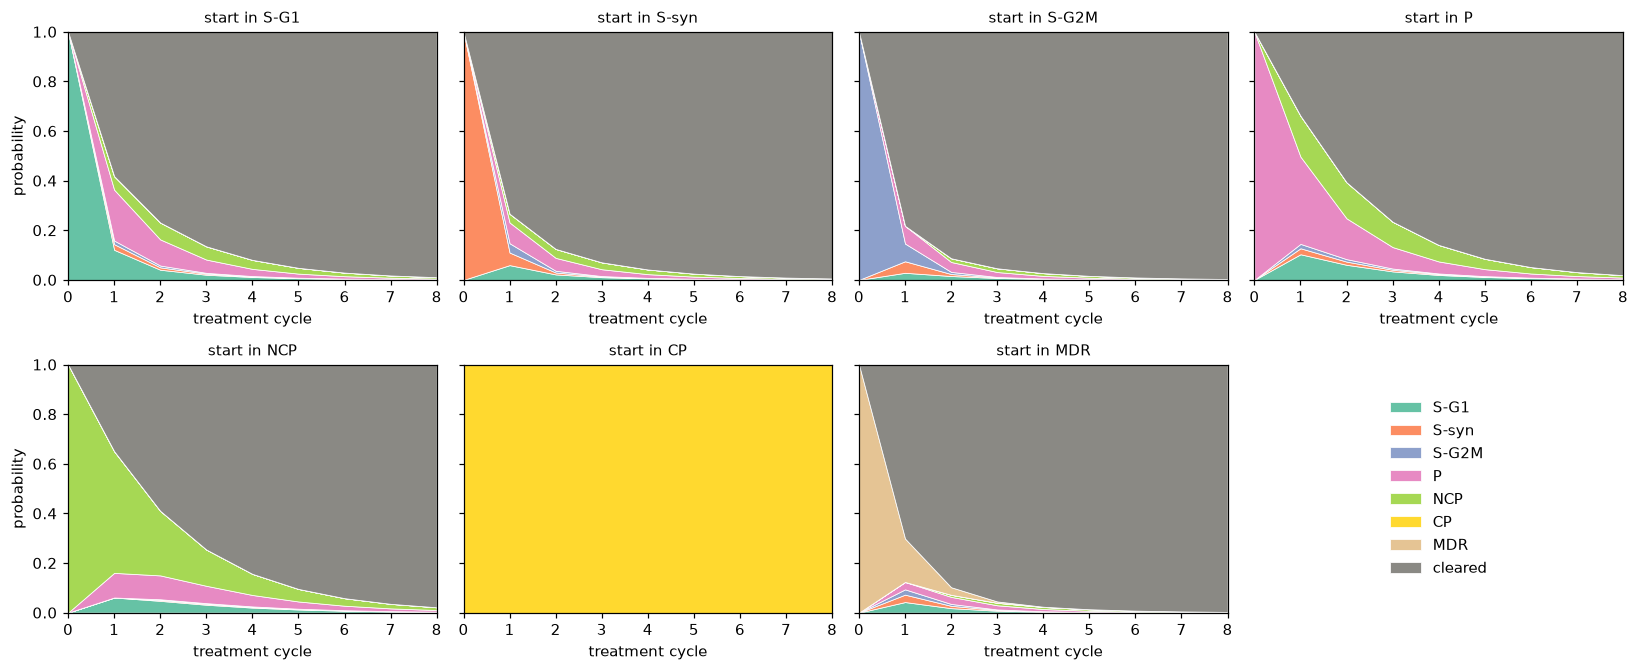

fraction alive after 4 cycles, starting in S-G1 : 0.081
fraction alive after 4 cycles, starting in S-syn : 0.042
fraction alive after 4 cycles, starting in S-G2M : 0.027
fraction alive after 4 cycles, starting in P : 0.141
fraction alive after 4 cycles, starting in NCP : 0.156
fraction alive after 4 cycles, starting in CP : 1.0
fraction alive after 4 cycles, starting in MDR : 0.024
fraction alive after 4 cycles, starting in cleared : 0.0


In [15]:
def plot_trajectory(traj, ax, title):
    t = np.arange(len(traj))
    ax.stackplot(t, traj.T, labels=OUTCOMES, colors=[STATE_COLORS[o] for o in OUTCOMES],
                 edgecolor="white", linewidth=0.5)
    ax.set_xlim(0, t[-1]); ax.set_ylim(0, 1)
    ax.set_title(title, fontsize=10); ax.set_xlabel("treatment cycle")

N_CYCLES = 8
fig, axes = plt.subplots(2, 4, figsize=(15, 6.2), sharey=True)
for ax, s in zip(axes.flat, STATES):
    plot_trajectory(evolve(basis(s, P_hat), P_hat, N_CYCLES), ax, f"start in {s}")

axes.flat[-1].axis("off")                                   # 7 states, 8 panels: use the last one for the legend
handles, labels = axes.flat[0].get_legend_handles_labels()
axes.flat[-1].legend(handles, labels, loc="center", frameon=False)

for ax in axes[:, 0]:
    ax.set_ylabel("probability")
plt.tight_layout()
plt.show()

alive3 = {s: 1 - evolve(basis(s, P_hat), P_hat, 4)[-1, -1] for s in OUTCOMES}
for s,v in alive3.items():
    print("fraction alive after 4 cycles, starting in", s, ":", round(v, 3))

<div class='alert alert-info'>
Use code as appropriate to answer the following questions.

- Which starting states does osimertinib completely eliminate (all probability ends in `cleared`)? Which ones survive?
- Of the states that can be cleared, which tumor lasts the longest?
- Which starting state sticks around for the most cycles of drug?
- Which starting state results in the highest proportion of alive cells after three cycles?</div>



In [31]:
cells_states = ['S-G1', 'S-syn', 'S-G2M', 'P', 'NCP', 'CP', 'MDR']

results = []

for state in cells_states:
    traj = evolve(basis(state, P_hat), P_hat, 8)
    df = pd.DataFrame(traj, columns=OUTCOMES).round(3)

    cleared_3 = df.loc[3, 'cleared']
    cleared_8 = df.loc[8, 'cleared']

    results.append({
        'Starting State': state,
        'Cleared After 3': cleared_3,
        'Cleared After 8': cleared_8
    })

results_df = pd.DataFrame(results)

results_df

,Starting State,Cleared After 3,Cleared After 8
0,S-G1,0.865,0.989
1,S-syn,0.929,0.994
2,S-G2M,0.953,0.996
3,P,0.766,0.981
4,NCP,0.746,0.978
5,CP,0.000,0.000
6,MDR,0.955,0.997


- Which starting states does osimertinib completely eliminate (all probability ends in `cleared`)? Which ones survive?

It looks like none of the starting states end up completely cleared. The closest is MDR, at a cleared probability of 99.7%. They are all above 97%, and each state continues to trend up, so perhaps with more cycles they could be cleared. 

- Of the states that can be cleared, which tumor lasts the longest?

Based on the graphs, it looks like the tumors starting in NCP stick around the longest, with P being roughly the same. NCP has the lowest cleared probability after 8 rounds outside of CP.

- Which starting state sticks around for the most cycles of drug?

Not counting CP, NCP sticks around for the longest when it is the starting state. Most of the other starting states are eliminated fairly early (within 2-3 rounds), but NCP sticks around for around 7 rounds. 

- Which starting state results in the highest proportion of alive cells after three cycles?

Not counting CP, NCP has the highest proportion of alive cells after 3 cycles, with 74.6% of cells cleared after three cycles. Once again, P was close behind.

### Starting from a mix of cell types
Use the distribution of states in timepoint A across all three experiments as a starting vector, $\pi_{0}$. Use this as your starting vector to evolve, and plot the result.

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,0.247,0.148,0.099,0.153,0.102,0.097,0.153,0.000
1,0.070,0.026,0.022,0.139,0.094,0.097,0.027,0.525
2,0.032,0.008,0.007,0.077,0.074,0.097,0.005,0.701
3,0.017,0.003,0.003,0.042,0.051,0.097,0.001,0.786
4,0.010,0.002,0.001,0.024,0.033,0.097,0.000,0.833
5,0.006,0.001,0.001,0.014,0.021,0.097,0.000,0.861
6,0.003,0.001,0.000,0.008,0.013,0.097,0.000,0.877
7,0.002,0.000,0.000,0.005,0.008,0.097,0.000,0.887
8,0.001,0.000,0.000,0.003,0.005,0.097,0.000,0.893


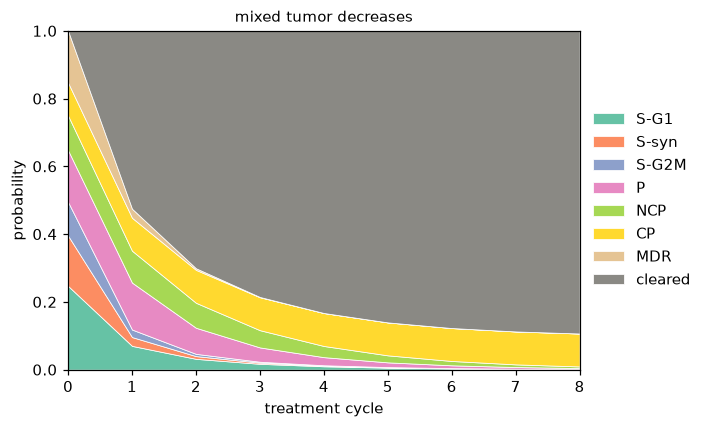

In [45]:
# starting vector
at_A = cells[cells["timepoint"] == "A"]
pi_mix = (at_A["state"]
          .value_counts(normalize=True)          
          .reindex(OUTCOMES, fill_value=0)       
          .to_numpy())


# evolve pi_mix
traj_mix = evolve(pi_mix, P_hat, N_CYCLES)
display(pd.DataFrame(traj_mix, columns=OUTCOMES).round(3))

# plot 
fig, ax = plt.subplots(figsize=(6, 4))
plot_trajectory(traj_mix, ax, "mixed tumor decreases")
ax.set_ylabel("probability")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.show()


<div class = "alert alert-info"> Which state ends up dominating the remaining cluster? Will these cells ever be cleared? How does the long-run endpoint relate to the transition matrix?</div>

Every cell out side of CP appears to drain to 0. CP starts at 9.7% and stays there throughout because it is an absorbing state as we found earlier in the transition matrix. 

## 4. Transition matrices for docetaxel and the drug holiday

Using the same approach in step 2 and step 3, answer the following questions.

1. What is the transition matrix under docetaxel and drug holiday, and how do they compare to osimertinib? Are there any absorbing states?
2. Simulate the mixed tumor under multiple rounds of docetaxel. What happens?

In [49]:
##Add code here
def transition_matrix(experiment):
    '''Square transition matrix for one experiment, as a DataFrame with rows and
    columns in OUTCOMES order (the same steps as Part 2).'''
    exp = cells[cells["experiment"] == experiment]
    at_A = exp[exp.timepoint == "A"][["lineage_tag", "state"]]
    at_B = exp[exp.timepoint == "B"][["lineage_tag", "state"]]
    pairs = pd.merge(at_A, at_B, on="lineage_tag", how="left", suffixes=("_A", "_B"))
    pairs["state_B"] = pairs["state_B"].fillna("cleared")   
    counts = (pd.crosstab(pairs.state_A, pairs.state_B)
                .reindex(index=STATES, columns=OUTCOMES, fill_value=0))
    P_exp = counts.div(counts.sum(axis=1), axis=0)
    P_exp.loc["cleared"] = [1.0 if c == "cleared" else 0.0 for c in OUTCOMES]   
    assert np.allclose(P_exp.sum(axis=1), 1), f"rows of the {experiment} matrix don't sum to 1"
    return P_exp

P_doc_df = transition_matrix("docetaxel")
P_holiday_df = transition_matrix("untreated")   


P_osi = P_hat.to_numpy()

P_doc = P_doc_df.to_numpy()

P_holiday = P_holiday_df.to_numpy()

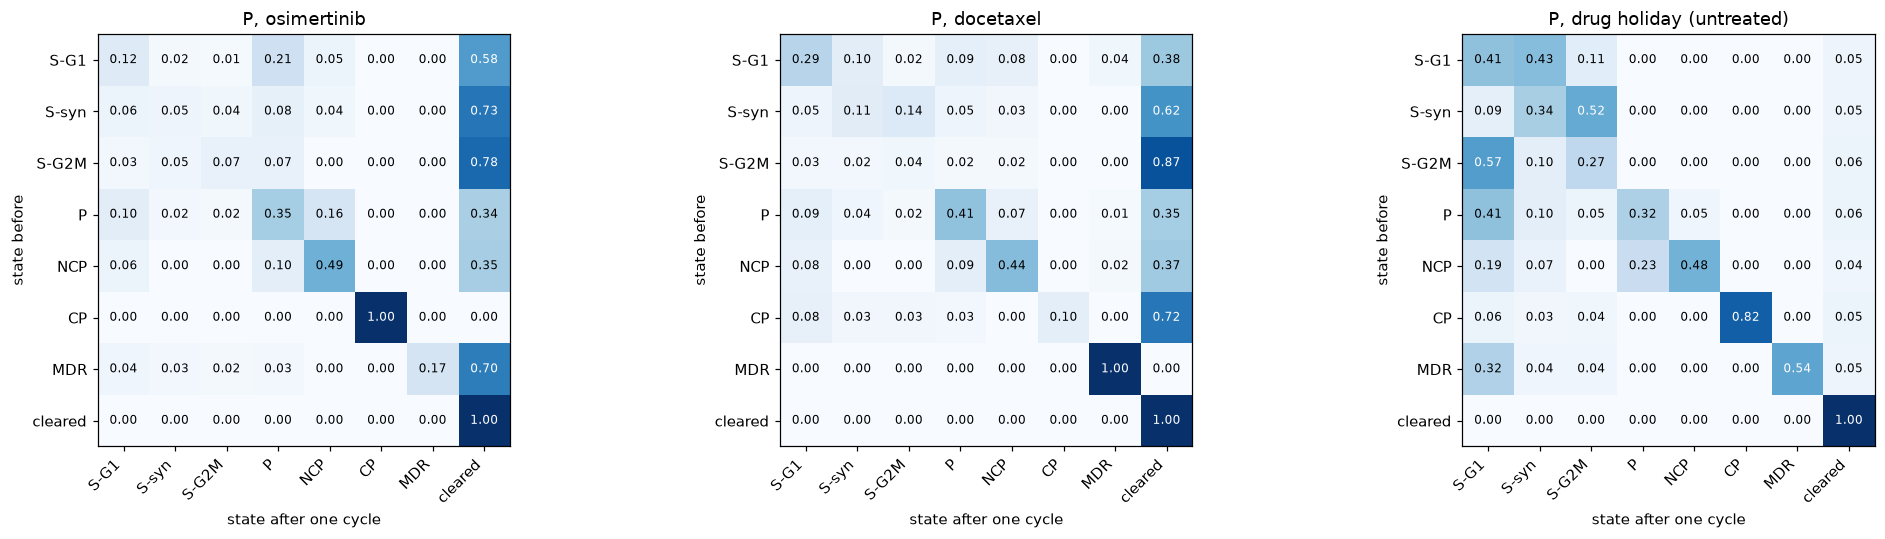

probability of staying in the same state for one cycle:


,osimertinib,docetaxel,holiday
S-G1,0.121,0.293,0.412
S-syn,0.051,0.111,0.342
S-G2M,0.071,0.035,0.269
P,0.352,0.409,0.324
NCP,0.490,0.436,0.478
CP,1.000,0.100,0.820
MDR,0.175,1.000,0.542
cleared,1.000,1.000,1.000


In [50]:
#Plot the transition matrices for docetaxel and the drug holiday.
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
show_matrix(P_hat, "P, osimertinib", axes[0])
show_matrix(P_doc_df, "P, docetaxel", axes[1])
show_matrix(P_holiday_df, "P, drug holiday (untreated)", axes[2])
plt.tight_layout()
plt.show()

# absorbing states
stay = pd.DataFrame({"osimertinib": np.diag(P_osi), "docetaxel": np.diag(P_doc),
                     "holiday": np.diag(P_holiday)}, index=OUTCOMES)
print("probability of staying in the same state for one cycle:")
stay.round(3)

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,0.247,0.148,0.099,0.153,0.102,0.097,0.153,0.000
1,0.112,0.054,0.036,0.107,0.083,0.010,0.166,0.434
2,0.053,0.023,0.014,0.065,0.055,0.001,0.174,0.615
3,0.027,0.011,0.006,0.038,0.034,0.000,0.178,0.705
4,0.015,0.006,0.003,0.022,0.020,0.000,0.180,0.754
5,0.008,0.003,0.002,0.013,0.012,0.000,0.181,0.781
6,0.005,0.002,0.001,0.007,0.007,0.000,0.182,0.797
7,0.003,0.001,0.001,0.004,0.004,0.000,0.182,0.805
8,0.002,0.001,0.000,0.002,0.002,0.000,0.183,0.810


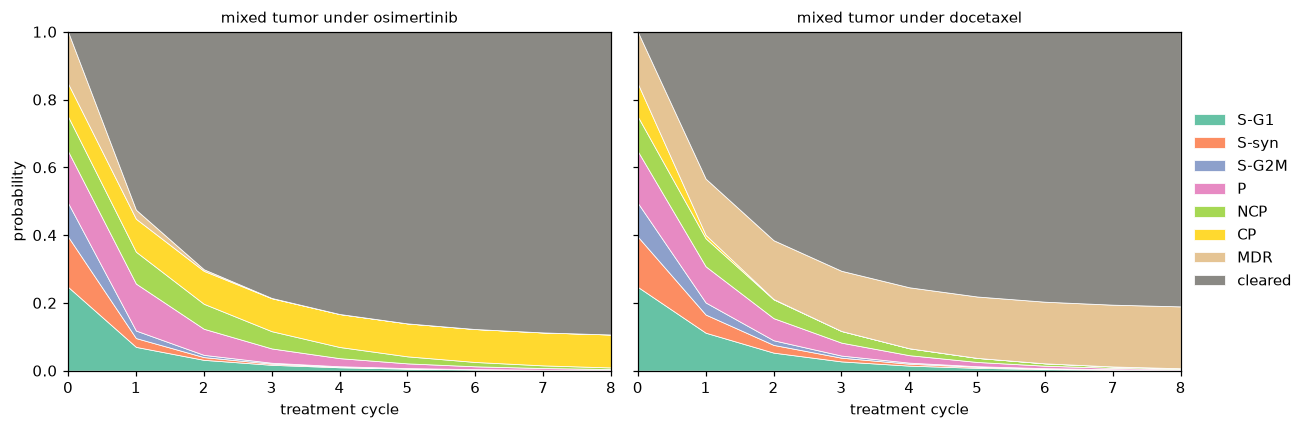

In [51]:
# Simulate the evolution of pi_mix under docetaxel
traj_mix_doc = evolve(pi_mix, P_doc, N_CYCLES)
display(pd.DataFrame(traj_mix_doc, columns=OUTCOMES).round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
plot_trajectory(evolve(pi_mix, P_osi, N_CYCLES), axes[0], "mixed tumor under osimertinib")
plot_trajectory(traj_mix_doc, axes[1], "mixed tumor under docetaxel")
axes[0].set_ylabel("probability")
axes[1].legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.tight_layout()
plt.show()

The transition matrices are fairly similar, as the most transitions occur along the diagonal. Most cells tend to stay the same state. The main difference is that Docetaxel's absorbing state is MDR, not CP. So it kills most of CP in a way that Osi cannot. Under multiple rounds of Docetaxel, there are still 19% of the cells alive in the tumor, which is worse than Osimertinib. 

## 5. Drug schedule strategies

We can answer a LOT of questions about what treatment strategy is best, just based on multiplying the transition matrices $P_{osi}, P_{doc},$ and $P_{holiday}$ together. Because matrix multiplication is linear, knowing what happens to the basis vectors under each drug tells us everything we need to know about the possibilities for mixed tumors. Use the transition matrices to do the following, running **8 cycles in each schedule**:
1. Compare 8 rounds of docetaxel and 8 rounds of osimertinib (done in step 4) to an alternating drug schedule.
   - For an alternating schedule, one *pair* of cycles multiplies by $P_{osi} P_{doc}$ and is considered 2 rounds of therapy.
2. Does it matter if we start with osimertinib or docetaxel when alternating treatments for this particular tumor?
3.  In what situation would a drug holiday help clear the tumor?
4. Test different combinations of starting states and treatment plans. Write a treatment prescription based on the general patterns you see. For example, If a tumor is entirely X cell type, treat with X. You do not need to enumerate the entire state space of possibilities, but a few clear strategies should emerge. In your treatment prescription, include the number of rounds of therapy needed. Keep in mind that fewer rounds is always better for patient health, but may not sufficiently clear the tumor. You can write this as a table or a short paragraph, but include your reasoning.

,alive,CP,MDR,expected survivors of 100 cells
osimertinib x8,0.1066,0.0972,0.0000,10.6650
docetaxel x8,0.1896,0.0000,0.1826,18.9634
"alternate, start O (ODOD...)",0.0094,0.0000,0.0007,0.9411
"alternate, start D (DODO...)",0.0092,0.0000,0.0003,0.9161


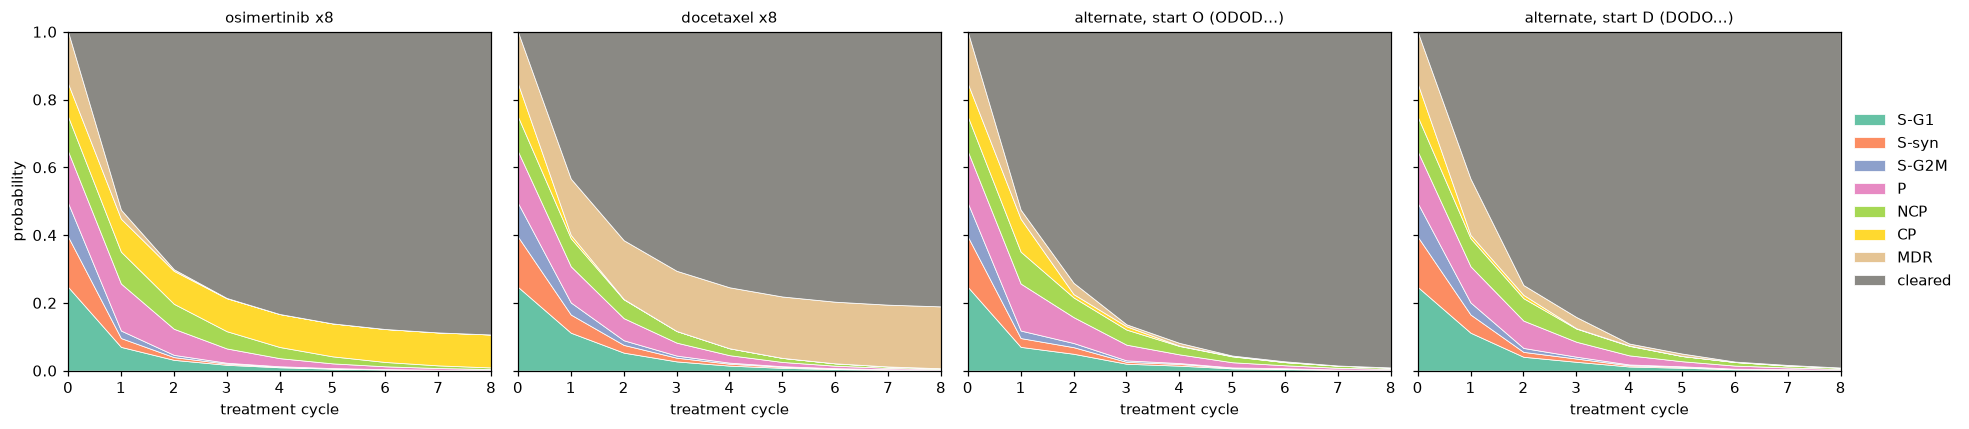

fraction of cells alive after 8 cycles (rows = plan, columns = starting tumor):


,measured mix,all S-G1,all S-syn,all S-G2M,all P,all NCP,all CP,all MDR
O x8,0.1066,0.0108,0.0056,0.0036,0.0190,0.0216,1.0000,0.0029
"(O,O,O,H) x2",0.0947,0.0205,0.0107,0.0068,0.0362,0.0418,0.7887,0.0058
"(O,O,H,H) x2",0.0979,0.0402,0.0214,0.0141,0.0709,0.0825,0.6366,0.0147
D x8,0.1896,0.0727,0.0124,0.0059,0.0545,0.0681,0.0101,1.0000
"(D,D,D,H) x2",0.1241,0.0606,0.0146,0.0067,0.0554,0.0657,0.0111,0.5884
"(O,D) x4",0.0094,0.0099,0.0051,0.0032,0.0170,0.0190,0.0064,0.0048
"(O,D,H,H) x2",0.0459,0.0438,0.0236,0.0150,0.0737,0.0835,0.0448,0.0390


cycles needed until a 100-cell tumor is expected to be cured (alive < 0.1%):


,measured mix,all S-G1,all S-syn,all S-G2M,all P,all NCP,all CP,all MDR
O only,>24,13,12,11,14,15,>24,11
D only,>24,>24,>24,>24,>24,>24,>24,>24
"alternate O,D",13,13,11,11,14,14,12,11
"alternate D,O",13,13,12,10,14,14,11,12
"O,O,H",>24,16,14,13,16,17,>24,13
"O,D,H",16,16,13,13,16,16,14,14


In [52]:
## Add code here
# One letter = one cycle: O = osimertinib, D = docetaxel, H = drug holiday (no drug)
MATS = {"O": P_osi, "D": P_doc, "H": P_holiday}

def run_schedule(pi0, schedule):
    '''schedule is a string like "OOOO", "ODOD" or "OOHH"; return the trajectory
    (row t = distribution after t cycles), like evolve().'''
    traj = [np.asarray(pi0, dtype=float)]
    for drug in schedule:
        traj.append(traj[-1] @ MATS[drug])
    return np.array(traj)

def summarize(final):
    return {"alive": 1 - final[-1],
            "CP": final[OUTCOMES.index("CP")],
            "MDR": final[OUTCOMES.index("MDR")],
            "expected survivors of 100 cells": 100 * (1 - final[-1])}

# --- Q1 and Q2: single drugs vs. alternating (8 cycles each), mixed tumor ---
SCHEDULES = {
    "osimertinib x8": "O" * 8,
    "docetaxel x8": "D" * 8,
    "alternate, start O (ODOD...)": "OD" * 4,
    "alternate, start D (DODO...)": "DO" * 4,
}
display(pd.DataFrame({name: summarize(run_schedule(pi_mix, s)[-1])
                      for name, s in SCHEDULES.items()}).T.round(4))

fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
for ax, (name, s) in zip(axes, SCHEDULES.items()):
    plot_trajectory(run_schedule(pi_mix, s), ax, name)
axes[0].set_ylabel("probability")
axes[-1].legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.tight_layout()
plt.show()

# --- Q3: when does a drug holiday help? alive fraction after 8 cycles, every starting state ---
HOLIDAY_PLANS = {
    "O x8": "O" * 8,
    "(O,O,O,H) x2": "OOOH" * 2,
    "(O,O,H,H) x2": "OOHH" * 2,
    "D x8": "D" * 8,
    "(D,D,D,H) x2": "DDDH" * 2,
    "(O,D) x4": "OD" * 4,
    "(O,D,H,H) x2": "ODHH" * 2,
}
tumors = {"measured mix": pi_mix, **{f"all {s}": basis(s, P_hat) for s in STATES}}
holiday_table = pd.DataFrame({t: {name: 1 - run_schedule(pi0, plan)[-1][-1]
                                  for name, plan in HOLIDAY_PLANS.items()}
                              for t, pi0 in tumors.items()})
print("fraction of cells alive after 8 cycles (rows = plan, columns = starting tumor):")
display(holiday_table.round(4))

# --- Q4: how many rounds does each plan need? ---
# "cured" here = expected survivors of a 100-cell tumor below 0.1, i.e. alive fraction < 0.001
def rounds_needed(pi0, pattern, threshold=0.001, max_cycles=24):
    '''Repeat `pattern` and return the first cycle count with alive fraction < threshold.'''
    sched = (pattern * max_cycles)[:max_cycles]
    alive = 1 - run_schedule(pi0, sched)[:, -1]
    hit = np.nonzero(alive < threshold)[0]
    return int(hit[0]) if len(hit) else f">{max_cycles}"

PATTERNS = {"O only": "O", "D only": "D", "alternate O,D": "OD", "alternate D,O": "DO",
            "O,O,H": "OOH", "O,D,H": "ODH"}
rounds_table = pd.DataFrame({t: {name: rounds_needed(pi0, p) for name, p in PATTERNS.items()}
                             for t, pi0 in tumors.items()})
print("cycles needed until a 100-cell tumor is expected to be cured (alive < 0.1%):")
rounds_table

1. Under osimertinib, about 10.7% of the cells remain alive, while 19% of them do under Docetaxel. When they are paired together in an alternating fashion, only about .9% of the mixed tumor cells survive. 

2. It does not appear to matter which drug we start the alternating pattern with, as both lead to rouhgly .9% of the cells being alive. 

3. A drug holiday helps to return resistant cells in absorbing states (CP or MDR) to non-absorbing states. An all CP tumor goes from 100% alive under osi to 64% under a cycle of osi and holidays. 

4. Alternating O and D cures the measured mix in about 13 cycles. To cure here means fewer than 0.1 expected survivors in a 100-cell tumor, a threshold taken from v2. Docetaxel alone never cures any tumor because S-G1 cells can turn into MDR.

## 4 · Simulate a tumor as collections of random walks

*For this section, use P = P_holiday to see how the cells would evolve without drug.*

The matrix calculation tracks *probabilities*. A **random walk tracks *one cell***: at each cycle, draw a random number and use the current row of $P$ to pick the next state. Many of the questions we are interested can be answered directly with the transition matrix. However, sometimes we are curious about the path of the cells overtime. For example, if the number of times we are in a particular state is meaningful, we need to count up that over time *for each individual cell* rather than considering overall probabilities. 

The row $P_{i\cdot}$ is a discrete distribution, so sampling from it is the **inverse-CDF method** from the CDF class: draw $U \sim \text{Uniform}(0,1)$ and pick the first state whose cumulative probability exceeds $U$.

For example, if the current row is
$(0.10, 0.03, 0.02, 0.20, 0.05, 0, 0, 0.60)$, the cumulative sums are
$(0.10, 0.13, 0.15, 0.35, 0.40, 0.40, 0.40, 1.00)$. A draw of $U = 0.31$
lands in the fourth interval, $(0.15, 0.35]$, so the next state is `P`.

In [53]:
rng = np.random.default_rng(100)

In [54]:
def step(i, P, rng):
    '''Given current state index i, draw the next state index.'''
    return int(rng.choice(len(P[i]), p=P[i]))


def random_walk(start, P, n_cycles, rng):
    '''Return a list of n_cycles + 1 state indices, beginning with start.'''
    path = [start]
    for _ in range(n_cycles):
        path.append(step(path[-1], P, rng))
    return path

In [55]:
P = np.array(P_holiday) #set P equal to the numpy array of the transition matrix from the untreated experiment    
start = OUTCOMES.index("S-G1")
for _ in range(5):
    print(" -> ".join(OUTCOMES[i] for i in random_walk(start, P, 8, rng)))

S-G1 -> S-syn -> S-G2M -> S-G1 -> S-G1 -> cleared -> cleared -> cleared -> cleared
S-G1 -> S-syn -> S-syn -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared
S-G1 -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared
S-G1 -> S-G2M -> S-G2M -> S-G2M -> S-G1 -> S-G1 -> S-G1 -> S-syn -> S-G1
S-G1 -> S-G1 -> S-syn -> S-G1 -> S-syn -> S-G1 -> S-syn -> S-G2M -> S-G1


Now run **100 walks from the mixed tumor** and look at them all at once.
Each walk's *starting* state is itself drawn from $\pi_{mix}$ with the same
inverse-CDF trick. Each row of the picture is one cell (sorted by starting
state); each column is one treatment cycle.

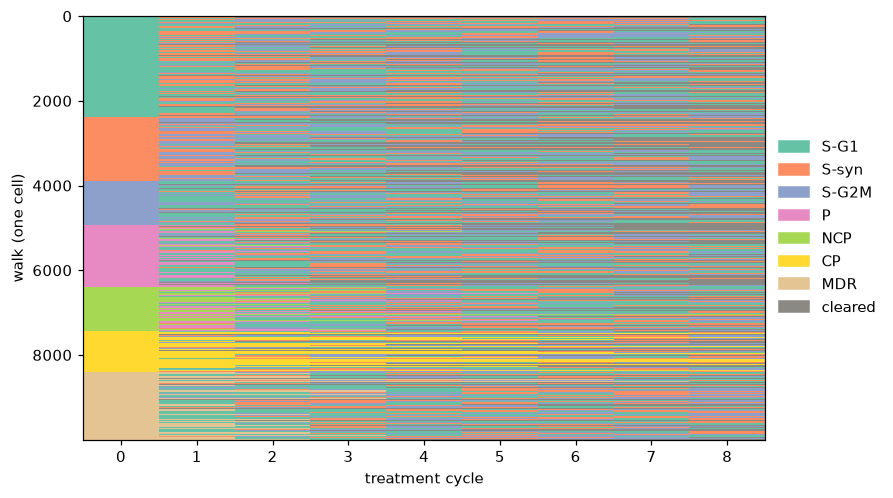

In [73]:
N_WALKS = 10000
starts = rng.choice(len(pi_mix), size=N_WALKS, p=pi_mix)
walks = np.array([random_walk(int(s0), P, N_CYCLES, rng) for s0 in starts])
walks = walks[np.argsort(walks[:, 0], kind="stable")]   # group rows by starting state

from matplotlib.colors import ListedColormap
fig, ax = plt.subplots(figsize=(8, 5))
ax.imshow(walks, cmap=ListedColormap([STATE_COLORS[s] for s in OUTCOMES]),
          vmin=-0.5, vmax=len(OUTCOMES) - 0.5, aspect="auto", interpolation="nearest")
ax.set_xlabel("treatment cycle"); ax.set_ylabel("walk (one cell)")
handles = [plt.Rectangle((0, 0), 1, 1, color=STATE_COLORS[s]) for s in OUTCOMES]
ax.legend(handles, OUTCOMES, loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.show()

**Compare the two methods.** The fraction of walks in each state at cycle $t$
is an estimate of $\pi_t$. Plot both.

In [74]:
frac = np.array([[np.mean(walks[:, t] == j) for j in range(len(OUTCOMES))]
                 for t in range(N_CYCLES + 1)])

sem = np.array([[np.std(walks[:, t] == j)/np.sqrt(len(walks)) for j in range(len(OUTCOMES))]
                 for t in range(N_CYCLES + 1)])

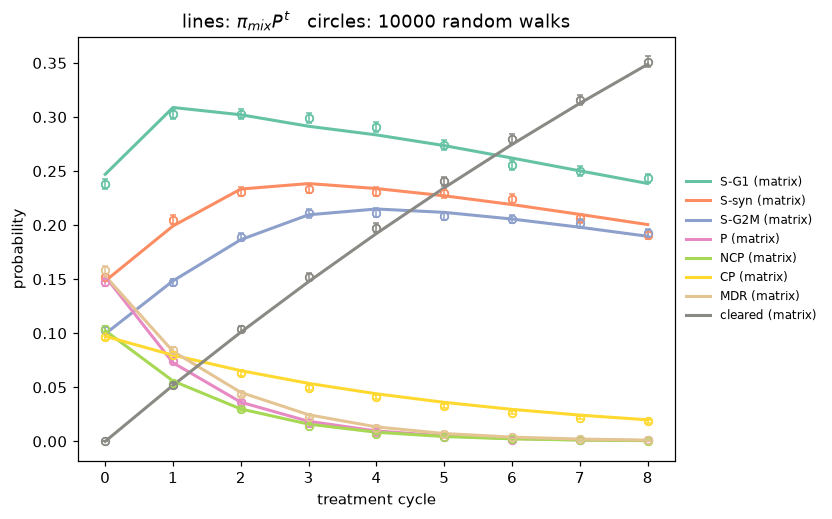

In [75]:
exact = evolve(pi_mix, P, N_CYCLES)
t = np.arange(N_CYCLES + 1)
fig, ax = plt.subplots(figsize=(7, 5))
for j, s in enumerate(OUTCOMES):
    ax.plot(t, exact[:, j], color=STATE_COLORS[s], lw=2, label=f"{s} (matrix)")
    ax.plot(t, frac[:, j], "o", color=STATE_COLORS[s], ms=5, mfc="none")
    ax.errorbar(t, frac[:, j], yerr=sem[:, j], fmt="o", color=STATE_COLORS[s],
            ms=5, mfc="none", capsize=2, elinewidth=1)
ax.set_xlabel("treatment cycle"); ax.set_ylabel("probability")
ax.set_title(f"lines: $\\pi_{{mix}} P^t$   circles: {N_WALKS} random walks")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False, fontsize=8)
plt.show()

We just simulated a tumor with 100 cells in it, and watched how it would evolve under no drug (drug holiday). Let's consider a different sized tumor.

<div class = 'alert alert-info'><b>Question:</b>

Re-run the last three cells with `N_WALKS = 10_000`. How does the gap between the circles and the lines change? Why?</div>

The circles lineup much better with N_WALKS = 10000 and their error bars are removed. This is a result of the error reducing in the tests due to the law of large numbers. More random walks reduces sampling error and produces more reliable estimates

## 5. What's the probability a drug will clear a tumor?

We've seen in a few different ways how to understand the dynamics of cells within one tumor. We can simulate many tumors in a similar way. This allows us to interpret the likely paths of whole tumors under different treatment options and investigate things like how often cells switch states or linger in the same state.

In [59]:
def simulate_tumor(pi0, P, n_cells, n_cycles, rng):
    '''Return an array of the final state index of each of n_cells cells. Each
    cell's starting state is drawn from pi0.'''
    starts = rng.choice(len(pi0), size=n_cells, p=pi0)
    return np.array([random_walk(int(s0), P, n_cycles, rng)[-1] for s0 in starts])

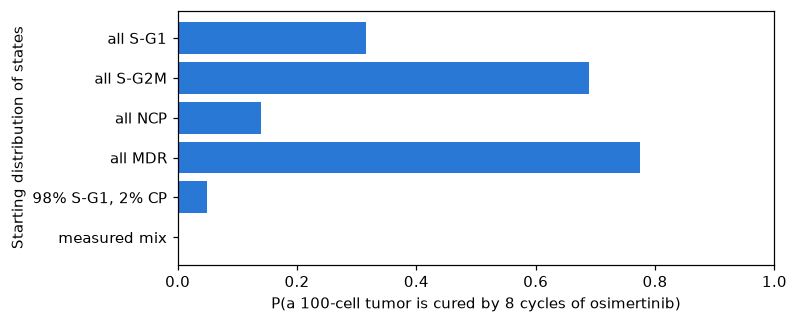

,P(cured),mean surviving cells,share of survivors that are CP
start,,,
all S-G1,0.315,1.105,0.000
all S-G2M,0.690,0.365,0.000
all NCP,0.140,2.095,0.000
all MDR,0.775,0.245,0.000
"98% S-G1, 2% CP",0.050,3.220,0.644
measured mix,0.000,10.780,0.910


In [60]:
N_CELLS, N_TUMORS = 100, 200
P_TUMOR, N_TUMOR_CYCLES = P_osi, 8      # this simulation: 8 cycles of osimertinib
scenarios = {
    "all S-G1":       basis("S-G1", P_hat),
    "all S-G2M":      basis("S-G2M", P_hat),
    "all NCP":         basis("NCP", P_hat),
    "all MDR":        basis("MDR", P_hat),
    "98% S-G1, 2% CP": 0.98 * basis("S-G1", P_hat) + 0.02 * basis("CP", P_hat),
    "measured mix":   pi_mix,
}
rows = []
for name, pi0 in scenarios.items():
    finals = np.array([simulate_tumor(pi0, P_TUMOR, N_CELLS, N_TUMOR_CYCLES, rng) for _ in range(N_TUMORS)])
    alive = (finals != OUTCOMES.index("cleared")).sum(axis=1)
    rows.append({"start": name,
                 "P(cured)": np.mean(alive == 0),
                 "mean surviving cells": alive.mean(),
                 "share of survivors that are CP":
                     (finals == OUTCOMES.index("CP")).sum() / max(alive.sum(), 1)})
results = pd.DataFrame(rows).set_index("start")

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(results.index[::-1], results["P(cured)"][::-1], color="#2a78d6")
ax.set_xlim(0, 1)
ax.set_xlabel(f"P(a {N_CELLS}-cell tumor is cured by {N_TUMOR_CYCLES} cycles of osimertinib)")
ax.set_ylabel("Starting distribution of states")
plt.show()
results.round(3)

<div class="alert alert-info"> Try rerunning the above code with all docetaxel. What do the results look like? </div>

The probabilities that the tumors in the bar chart are cured goes way down for all tumors except the all S-G2M tumor. The share of survivors that are CP are all 0. 

## 6. Investigating the persister state

Something important about the persister cells (P and NCP) not yet included in this model is their ability to pick up *permanent* mutations that allow them to be *permanently resistant (PR).* In other words, if a cell stays in the persister state for too long, it will switch to a new absorbing state not in our data. We don't have this in our dataset, so we can't estimate the transition probability of P -> PR or NCP -> PR to add it to our matrix.

We know that if a cell stays in P or NCP for too long, it will eventually become permanently resistant. We will incorporate this into the model by assuming that **if a P or NCP cell stays in a persister state for 3 or more cycles, it will become permanently resistant.** So we want to look at the random walks of cells themselves and see what percentage of cells in a tumor stay in P or NCP for **3 or more** drug cycles. 

Let's look at 100 tumors of 1000 cells each under osimertinib treatment over 8 cycles. 

osimertinib x8: permanently resistant fraction = 8.15% +/- 0.09% (SEM)
95% CI: (7.97%, 8.32%)
one-sample t-test vs 10%: t = -20.83, p = 5.69e-38
tumors with more than 10% PR cells: 1%


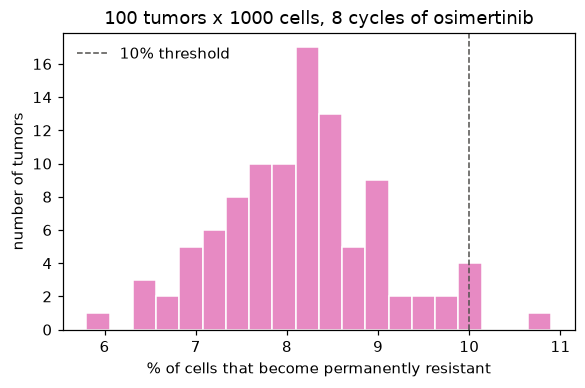

In [78]:
# write a function that runs 1000 random walks and saves them
# you will use this function 100 times to generate a simulated set of tumors
from scipy import stats

PERSISTER = [OUTCOMES.index("P"), OUTCOMES.index("NCP")]
MATS = {"O": P_osi, "D": P_doc, "H": P_holiday}   # one letter = one cycle (same letters as Section 5)

def simulate_walks(pi0, schedule, n_cells, rng):
    '''Run n_cells random walks at once (one per cell) with the inverse-CDF method.
    schedule is a string like "OOOOOOOO", one letter per cycle.
    Returns an (n_cells, len(schedule) + 1) array of state indices: column t = state after t cycles.'''
    n_states = len(pi0)
    states = np.searchsorted(np.cumsum(pi0), rng.random(n_cells), side="right")
    states = np.minimum(states, n_states - 1)                    # guard against round-off
    walks = [states]
    for drug in schedule:
        cdf = np.cumsum(MATS[drug], axis=1)[states]              # each cell's current row of P, as a CDF
        u = rng.random(n_cells)[:, None]
        states = np.minimum((u > cdf).sum(axis=1), n_states - 1) # first state whose CDF exceeds u
        walks.append(states)
    return np.column_stack(walks)

# go through each random walk and if a persister stays for 3+ consecutive cycles, add to tally
def longest_persister_run(walks):
    '''Longest number of consecutive cycles each cell spends in P or NCP (switching
    between P and NCP still counts as staying a persister). Column 0 is the starting
    state before any drug, so only the states after each cycle (columns 1..n) count.'''
    in_persister = np.isin(walks[:, 1:], PERSISTER)
    run = np.zeros(len(walks), dtype=int)
    longest = np.zeros(len(walks), dtype=int)
    for col in in_persister.T:
        run = np.where(col, run + 1, 0)          # extend the streak, or reset it to 0
        longest = np.maximum(longest, run)
    return longest

# count up cells that stayed in persister state consecutively out of total cells
def fraction_PR(pi0, schedule, n_cells, rng, min_run=3):
    '''Fraction of a tumor's cells that become permanently resistant (3+ consecutive persister cycles).'''
    walks = simulate_walks(pi0, schedule, n_cells, rng)
    return np.mean(longest_persister_run(walks) >= min_run)

# repeat for all tumors
N_CELLS_PR, N_TUMORS_PR, N_CYCLES_PR = 1000, 100, 8
rng_pr = np.random.default_rng(2026)
frac_osi = np.array([fraction_PR(pi_mix, "O" * N_CYCLES_PR, N_CELLS_PR, rng_pr)
                     for _ in range(N_TUMORS_PR)])

# report mean +/- SEM for osimertinib
mean_osi = frac_osi.mean()
sem_osi = frac_osi.std(ddof=1) / np.sqrt(N_TUMORS_PR)
ci_low, ci_high = stats.t.interval(0.95, df=N_TUMORS_PR - 1, loc=mean_osi, scale=sem_osi)
print(f"osimertinib x{N_CYCLES_PR}: permanently resistant fraction = {100*mean_osi:.2f}% +/- {100*sem_osi:.2f}% (SEM)")
print(f"95% CI: ({100*ci_low:.2f}%, {100*ci_high:.2f}%)")

# compare to 10% threshold using 95% CI or a hypothesis test
t_stat, p_val = stats.ttest_1samp(frac_osi, 0.10)
print(f"one-sample t-test vs 10%: t = {t_stat:.2f}, p = {p_val:.3g}")
print(f"tumors with more than 10% PR cells: {100*np.mean(frac_osi > 0.10):.0f}%")

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(100 * frac_osi, bins=20, color=STATE_COLORS["P"], edgecolor="white")
ax.axvline(10, color="#52514e", ls="--", lw=1, label="10% threshold")
ax.set_xlabel("% of cells that become permanently resistant")
ax.set_ylabel("number of tumors")
ax.set_title(f"{N_TUMORS_PR} tumors x {N_CELLS_PR} cells, {N_CYCLES_PR} cycles of osimertinib")
ax.legend(frameon=False)
plt.show()

<div class="alert alert-info"> What percentage of tumors under the following treatments have more than 10% permanently resistant cells? How does this change as you increase the number of cycles?

- Osimertinib alone
- Doxetaxel alone
- Alternating OD
- Doxetaxel with drug holiday
</div>

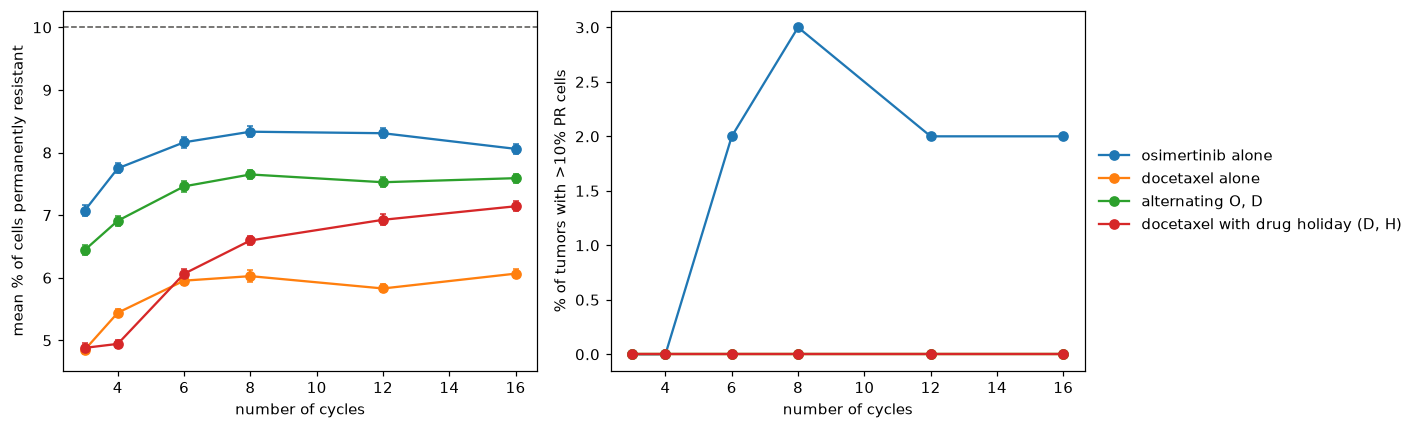

% of tumors with more than 10% permanently resistant cells:


cycles,3,4,6,8,12,16
treatment,,,,,,
osimertinib alone,0.0,0.0,2.0,3.0,2.0,2.0
docetaxel alone,0.0,0.0,0.0,0.0,0.0,0.0
"alternating O, D",0.0,0.0,0.0,0.0,0.0,0.0
"docetaxel with drug holiday (D, H)",0.0,0.0,0.0,0.0,0.0,0.0


mean % of permanently resistant cells per tumor:


cycles,3,4,6,8,12,16
treatment,,,,,,
osimertinib alone,7.07,7.75,8.16,8.33,8.31,8.06
docetaxel alone,4.85,5.44,5.95,6.03,5.83,6.07
"alternating O, D",6.44,6.91,7.46,7.65,7.53,7.59
"docetaxel with drug holiday (D, H)",4.88,4.94,6.06,6.60,6.93,7.14


In [79]:
# Compare treatments and numbers of cycles (same 100 tumors x 1000 cells, starting from pi_mix)
TREATMENTS = {
    "osimertinib alone": "O",
    "docetaxel alone": "D",
    "alternating O, D": "OD",
    "docetaxel with drug holiday (D, H)": "DH",
}
CYCLE_COUNTS = [3, 4, 6, 8, 12, 16]

rows = []
for name, pattern in TREATMENTS.items():
    for n in CYCLE_COUNTS:
        schedule = (pattern * n)[:n]              # repeat the pattern out to n cycles
        fr = np.array([fraction_PR(pi_mix, schedule, N_CELLS_PR, rng_pr) for _ in range(N_TUMORS_PR)])
        rows.append({"treatment": name, "cycles": n,
                     "mean % PR cells": 100 * fr.mean(),
                     "SEM": 100 * fr.std(ddof=1) / np.sqrt(N_TUMORS_PR),
                     "% of tumors with >10% PR": 100 * np.mean(fr > 0.10)})
pr_table = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, sub in pr_table.groupby("treatment", sort=False):
    axes[0].errorbar(sub["cycles"], sub["mean % PR cells"], yerr=sub["SEM"], marker="o", capsize=2, label=name)
    axes[1].plot(sub["cycles"], sub["% of tumors with >10% PR"], marker="o", label=name)
axes[0].axhline(10, color="#52514e", ls="--", lw=1)
axes[0].set_ylabel("mean % of cells permanently resistant")
axes[1].set_ylabel("% of tumors with >10% PR cells")
for ax in axes:
    ax.set_xlabel("number of cycles")
axes[1].legend(frameon=False, loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()

print("% of tumors with more than 10% permanently resistant cells:")
display(pr_table.pivot(index="treatment", columns="cycles", values="% of tumors with >10% PR")
                .reindex(TREATMENTS))
print("mean % of permanently resistant cells per tumor:")
pr_table.pivot(index="treatment", columns="cycles", values="mean % PR cells").reindex(TREATMENTS).round(2)

What percentage of tumors under the following treatments have more than 10% permanently resistant cells? How does this change as you increase the number of cycles?

- Osimertinib alone
- Doxetaxel alone
- Alternating OD
- Doxetaxel with drug holiday


Osimertinib alone produces the most permanently resistent cells because it keps cells in P and NCP the most. It is actually the only treatment plan that has tumors with over than 10% permanently resistant cells based on this data, with 2% of tumors fitting that criteria for 6, 12, and 16 cycles, and 3% for 8 cycles. 

As you increase the number of cycles, generally the number of permanently resistant cells on average increase. The worst is Docetaxel with breaks, as it climbs from 4.88% mean of resistant cells to 7.14%. After 16 cycles, Docetaxel alone appears to have performed the best in this metric, with only 6.07% of cells on average being permanently resistant to treatment. 